# Домашнее задание "Корреляционный и регрессионный анализ"

**Инструкции:**
- Скачайте файл `practical_module_dataset.csv` и заполните ячейки с заданиями кодом и выводами.
- В каждой задаче требуется:
  - короткая формулировка метода и обоснование,
  - код/расчёты,
  - результаты (коэффициенты, статистики, p-value, CI, R²),
  - промежуточный вывод.
- Используйте `numpy`, `pandas`, `scipy`, `statsmodels` или `scikit-learn` по желанию. При необходимости предобработки данных (очистка, удаление пропусков) укажите свои действия.
- Для воспроизводимости задан `np.random.seed` - не меняйте его!

**Формат сдачи:** `.ipynb` с заполненными ячейками, кодом и выводами.

**Источник данных:** только приложенный `practical_module_dataset.csv` (30 наблюдений, 8 столбцов). Синтетические наблюдения не создаются. `random_state` нужен для воспроизводимого разбиения выборки, а генератор случайных индексов — только для бутстрэпа существующих строк CSV.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from IPython.display import display

np.random.seed(28)

In [2]:

from pathlib import Path
source_path = Path('practical_module_dataset.csv')
if not source_path.is_file():
    raise FileNotFoundError(f'Не найден входной CSV: {source_path.resolve()}')
df = pd.read_csv(source_path)
print(f'Источник данных: {source_path.resolve()}')
print(f'Исходная выборка: {df.shape[0]} строк, {df.shape[1]} столбцов')
print('Первые 5 строк исходного CSV:')
display(df.head())


Источник данных: /Users/nikita/code/maga/math_stat_1/dz2/practical_module_dataset.csv
Исходная выборка: 30 строк, 8 столбцов
Первые 5 строк исходного CSV:


,id,age,height_cm,weight_kg,iq,tv_hours,study_hours,score
0,1,24,155.2,51.37,91,11,11.9,76.5
1,2,37,184.9,76.49,90,15,4.0,65.4
2,3,32,169.8,64.24,98,6,10.6,78.2
3,4,28,173.6,68.22,88,9,9.2,75.6
4,5,25,174.2,73.80,102,8,8.0,75.1


### Задание 1.
Выполните первичный анализ данных (EDA):
1. посмотрите на `describe()` для всех переменных,
2. проверьте наличие пропусков и типы данных через `info()`,
3. запишите наблюдения в текстовой ячейке.

**Метод.** Проверяем типы, пропуски и дубликаты; по гистограммам всех числовых столбцов оцениваем форму распределений и возможные выбросы. `id` — идентификатор, а не содержательный признак.

Типы и полнота данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           30 non-null     int64  
 1   age          30 non-null     int64  
 2   height_cm    30 non-null     float64
 3   weight_kg    30 non-null     float64
 4   iq           30 non-null     int64  
 5   tv_hours     30 non-null     int64  
 6   study_hours  30 non-null     float64
 7   score        30 non-null     float64
dtypes: float64(4), int64(4)
memory usage: 2.0 KB

Количество пропусков по столбцам:
id             0
age            0
height_cm      0
weight_kg      0
iq             0
tv_hours       0
study_hours    0
score          0

Количество полностью дублирующихся строк: 0

Описательная статистика:


,count,mean,std,min,25%,50%,75%,max
id,30.0,15.500000,8.803408,1.00,8.2500,15.500,22.7500,30.00
age,30.0,29.400000,6.672641,18.00,24.2500,29.000,35.5000,39.00
height_cm,30.0,169.153333,9.584101,148.20,163.2500,169.750,174.1000,185.80
weight_kg,30.0,62.734000,9.201488,44.75,56.6225,63.675,68.6025,81.13
iq,30.0,100.433333,12.119188,82.00,91.0000,97.000,109.7500,132.00
tv_hours,30.0,12.266667,3.832109,6.00,9.0000,12.000,14.0000,22.00
study_hours,30.0,7.640000,3.281568,2.70,4.9750,7.650,9.4500,14.40
score,30.0,73.400000,8.253693,58.90,67.8000,74.300,78.7250,91.50


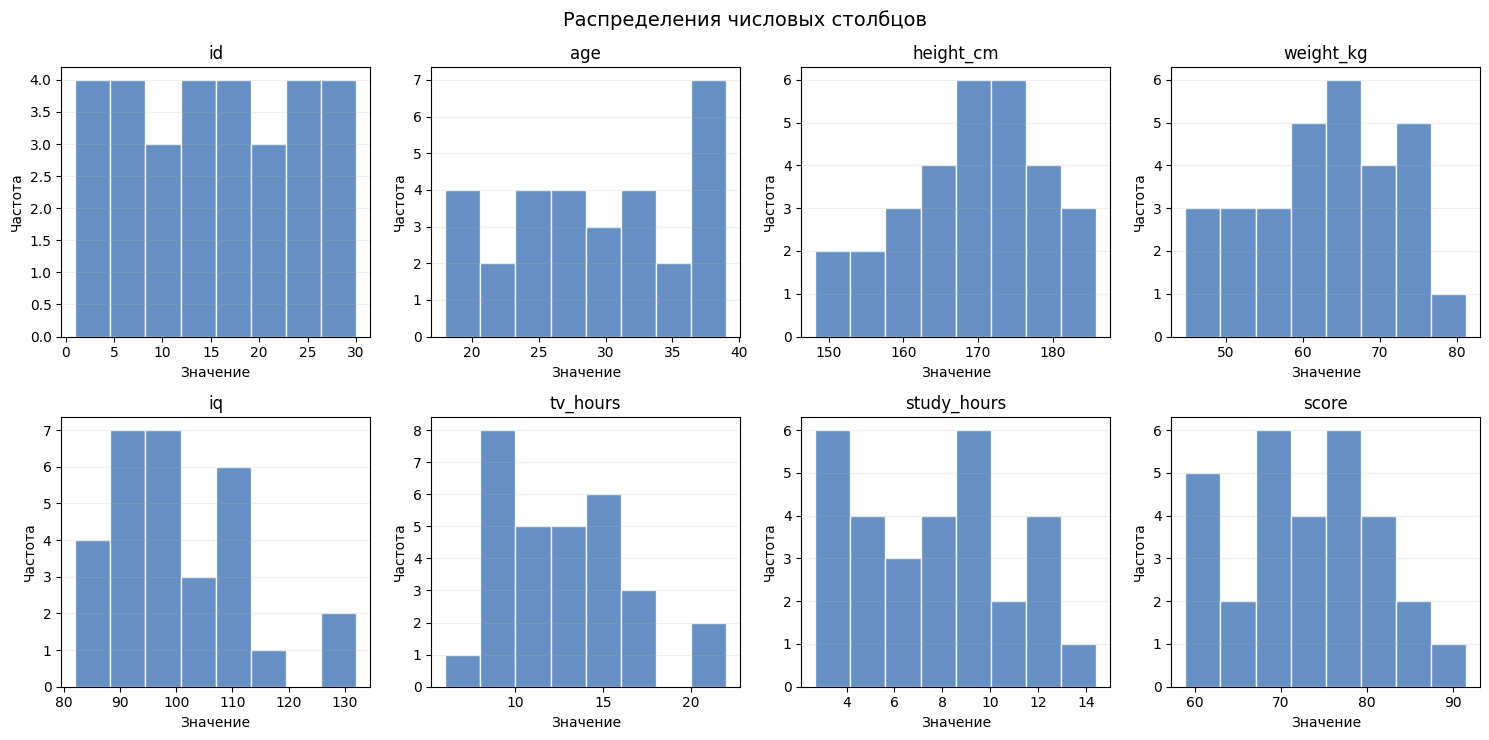

Строк после очистки: 30 (удалено 0).


In [3]:
print('Типы и полнота данных:')
df.info()
print('\nКоличество пропусков по столбцам:')
print(df.isna().sum().to_string())
print(f'\nКоличество полностью дублирующихся строк: {df.duplicated().sum()}')
print('\nОписательная статистика:')
display(df.describe(include='all').T)

numeric_columns = df.select_dtypes(include='number').columns.tolist()
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for ax, col in zip(axes.flat, numeric_columns):
    ax.hist(df[col].dropna(), bins=8, color='#4B7DBA', alpha=0.85, edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel('Значение')
    ax.set_ylabel('Частота')
    ax.grid(axis='y', alpha=0.2)
for ax in axes.flat[len(numeric_columns):]:
    ax.set_visible(False)
fig.suptitle('Распределения числовых столбцов', fontsize=14)
plt.tight_layout()
plt.show()

# Удаляем точные дубликаты и строки с пропущенными значениями в используемых признаках.
# На данном наборе очистка ничего не удаляет, но делает шаг воспроизводимым.
required_columns = ['age', 'height_cm', 'weight_kg', 'iq', 'tv_hours', 'study_hours', 'score']
df_clean = df.drop_duplicates().dropna(subset=required_columns).reset_index(drop=True).copy()
print(f'Строк после очистки: {len(df_clean)} (удалено {len(df) - len(df_clean)}).')

Пропусков и полных дубликатов нет, поэтому после очистки остались все 30 наблюдений; все 8 столбцов имеют числовые типы. Распределения возраста, роста, веса, времени учёбы и баллов относительно симметричны, у `iq` и `tv_hours` заметна правосторонняя асимметрия, а два значения `tv_hours = 22` выглядят высокими выбросами; `id` — порядковый идентификатор.

### Задание 2.
1. Постройте scatter plot по признакам `height_cm` и `weight_kg`.
2. Посчитайте коэффициент Пирсона между `height_cm` и `weight_kg` и выведите его на экран.
3. Интерпретируйте результат и запишите в виде мини-вывода.

**Метод.** Для двух количественных переменных используем коэффициент корреляции Пирсона и двустороннюю проверку нулевой гипотезы об отсутствии линейной корреляции.

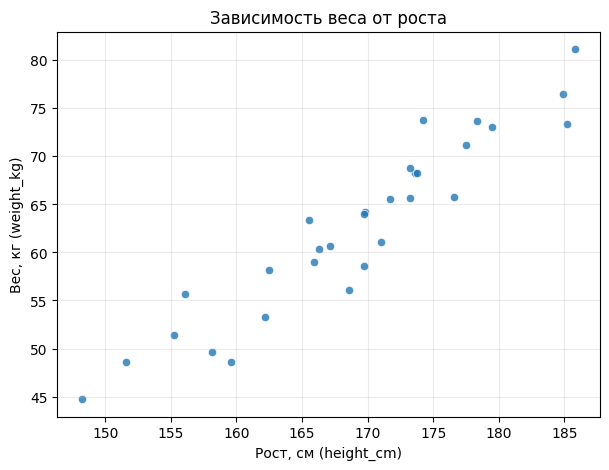

Корреляция Пирсона: r = 0.9435; p-value = 5.799e-15


In [4]:
x_height = df_clean['height_cm']
y_weight = df_clean['weight_kg']
r_pearson, p_pearson = stats.pearsonr(x_height, y_weight)

plt.figure(figsize=(7, 5))
plt.scatter(x_height, y_weight, alpha=0.8, edgecolors='white', linewidth=0.6)
plt.xlabel('Рост, см (height_cm)')
plt.ylabel('Вес, кг (weight_kg)')
plt.title('Зависимость веса от роста')
plt.grid(alpha=0.25)
plt.show()
print(f'Корреляция Пирсона: r = {r_pearson:.4f}; p-value = {p_pearson:.3e}')

Между ростом и весом наблюдается очень сильная положительная линейная связь (`r = 0.944`). Корреляция статистически значима (`p < 0.001`), поэтому гипотеза об отсутствии линейной корреляции отвергается на уровне 0.05.

### Задание 3.
1. Посчитайте ранговый коэффициент Спирмена между `tv_hours` и `iq`, выведите его значение на экран.
2. Оцените, есть ли связь? Запишите наблюдения в виде короткого вывода.

**Метод.** Коэффициент Спирмена оценивает монотонную связь между ранжированными значениями `tv_hours` и `iq`, не требуя линейности зависимости.

In [5]:
rho_spearman, p_spearman = stats.spearmanr(
    df_clean['tv_hours'], df_clean['iq']
)
print(f'Корреляция Спирмена: rho = {rho_spearman:.4f}; p-value = {p_spearman:.4f}')

Корреляция Спирмена: rho = -0.2108; p-value = 0.2635


Обнаружена слабая отрицательная ранговая корреляция (`rho = -0.211`), но она статистически незначима (`p = 0.264 > 0.05`). Данных недостаточно для вывода о монотонной связи между временем просмотра ТВ и IQ.

### Задание 4.
1. Постройте простую линейную регрессию `weight_kg ~ height_cm`.
2. Найдите и выведите оценки коэффициентов (intercept и slope).
3. Рассчитайте и вывдите 95% доверительный интервал для наклона.
4. Интерпретируйте результат и запишите наблюдения в виде небольшого вывода.

**Метод.** Оцениваем линейную регрессию `weight_kg ~ height_cm` методом наименьших квадратов (OLS) с константой; 95%-й доверительный интервал наклона берём из оценённой модели.

In [6]:
X_weight = sm.add_constant(df_clean[['height_cm']], has_constant='add')
model_weight = sm.OLS(df_clean['weight_kg'], X_weight).fit()
intercept_weight = model_weight.params['const']
slope_weight = model_weight.params['height_cm']
ci_slope = model_weight.conf_int(alpha=0.05).loc['height_cm']
print(f'Intercept = {intercept_weight:.4f} кг')
print(f'Slope = {slope_weight:.4f} кг/см')
print(f'95% CI slope = [{ci_slope.iloc[0]:.4f}, {ci_slope.iloc[1]:.4f}] кг/см')
print(f'p-value slope = {model_weight.pvalues["height_cm"]:.3e}')

Intercept = -90.4962 кг
Slope = 0.9059 кг/см
95% CI slope = [0.7827, 1.0290] кг/см
p-value slope = 5.799e-15


По модели при увеличении роста на 1 см ожидаемый вес увеличивается в среднем на `0.906` кг; свободный член равен `-90.496` кг и вне наблюдаемого диапазона роста не имеет самостоятельной практической интерпретации. 95%-й ДИ наклона `[0.783; 1.029]` кг/см не содержит нуль, что указывает на статистически значимую положительную связь.

### Задание 5.
Для `height_cm = 175`:
1. вычислите предсказание веса,
2. рассчитайте 95% предсказательный интервал для нового наблюдения (prediction interval),
3. запишите небольшой вывод.

**Метод.** Используем `get_prediction(...).summary_frame(alpha=0.05)`; для отдельного будущего наблюдения нужны границы `obs_ci_lower` и `obs_ci_upper`, а не доверительный интервал среднего отклика.

In [7]:
new_height = pd.DataFrame({'height_cm': [175.0]})
X_new = sm.add_constant(new_height, has_constant='add')
prediction_frame = model_weight.get_prediction(X_new).summary_frame(alpha=0.05)
predicted_weight = prediction_frame['mean'].iloc[0]
pred_low = prediction_frame['obs_ci_lower'].iloc[0]
pred_high = prediction_frame['obs_ci_upper'].iloc[0]
print(f'Прогноз веса при росте 175 см = {predicted_weight:.3f} кг')
print(f'95% предсказательный интервал = [{pred_low:.3f}, {pred_high:.3f}] кг')
display(prediction_frame[['mean', 'obs_ci_lower', 'obs_ci_upper']].round(3))

Прогноз веса при росте 175 см = 68.030 кг
95% предсказательный интервал = [61.531, 74.530] кг


,mean,obs_ci_lower,obs_ci_upper
0,68.03,61.531,74.53


Для человека ростом `175` см прогнозируемый вес составляет `68.03` кг. 95%-й предсказательный интервал для **одного нового** наблюдения — `[61.53; 74.53]` кг; он включает как неопределённость регрессионной оценки, так и индивидуальную вариацию веса при данном росте.

### Задание 6.
1. Постройте множественную регрессию `score ~ study_hours + iq + tv_hours + age`.
2. Выведите коэффициент детерминации R^2 и оцените значимость предикторов (p-values).
3. Запишите наблюдения в вывод.

**Метод.** Строим множественную OLS-регрессию с константой и четырьмя предикторами; значимость каждого коэффициента оцениваем по его `p-value` при контроле остальных переменных.

In [8]:
features = ['study_hours', 'iq', 'tv_hours', 'age']
X_score = sm.add_constant(df_clean[features], has_constant='add')
y_score = df_clean['score']
model_score = sm.OLS(y_score, X_score).fit()
coefficients = pd.DataFrame({
    'coef': model_score.params,
    'std_error': model_score.bse,
    'p_value': model_score.pvalues,
})
print('Оценки коэффициентов, стандартные ошибки и p-values:')
display(coefficients.round(6))
print(f'R² = {model_score.rsquared:.4f}')
print(f'Скорректированный R² = {model_score.rsquared_adj:.4f}')
print('Значимые предикторы (p < 0.05):',
      ', '.join(model_score.pvalues.drop('const').loc[lambda s: s < 0.05].index))

Оценки коэффициентов, стандартные ошибки и p-values:


,coef,std_error,p_value
const,45.658396,6.806993,0.000000
study_hours,2.097834,0.193392,0.000000
iq,0.147930,0.053118,0.010059
tv_hours,-0.144698,0.158558,0.370176
age,-0.046532,0.091130,0.614106


R² = 0.8741
Скорректированный R² = 0.8539
Значимые предикторы (p < 0.05): study_hours, iq


Модель объясняет `87.4%` вариации `score` в исходной выборке (`R² = 0.8741`). При контроле других переменных значимы `study_hours` (`β = 2.098`, `p < 0.001`) и `iq` (`β = 0.148`, `p = 0.010`), тогда как `tv_hours` (`p = 0.370`) и `age` (`p = 0.614`) статистически незначимы.

### Задание 7.
1. Разделите данные на train/test (70/30), используйте `random_state=42`.
2. Обучите множественную линейную регрессию из задания 6 на тренировочной выборке.
3. И оцените RMSE на тестовой выборке - выведите её на экран.
4. Насколько модель хорошо предсказывает целевую переменную?

**Метод.** Делаем разбиение 70/30 с `random_state=42`, обучаем OLS только на train и вычисляем RMSE прогнозов на ранее не виденной test-выборке.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df_clean[features], df_clean['score'], test_size=0.30, random_state=42
)
X_train_const = sm.add_constant(X_train, has_constant='add')
X_test_const = sm.add_constant(X_test, has_constant='add')
model_score_train = sm.OLS(y_train, X_train_const).fit()
y_pred_test = model_score_train.predict(X_test_const)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
print(f'Train: {len(y_train)} наблюдений; test: {len(y_test)} наблюдений')
print(f'RMSE на test = {rmse_test:.4f} балла')
print(f'Стандартное отклонение score во всей выборке = {df_clean["score"].std():.4f} балла')

Train: 21 наблюдений; test: 9 наблюдений
RMSE на test = 3.7936 балла
Стандартное отклонение score во всей выборке = 8.2537 балла


Тестовая `RMSE = 3.79` балла при стандартном отклонении `score` около `8.25` балла, то есть ошибка прогноза сравнительно невелика относительно разброса целевой переменной. Однако test включает только 9 наблюдений, поэтому оценка качества может быть нестабильной.

### Задание 8.
1. Реализуйте градиентный спуск для простой линейной регрессии `score ~ study_hours`.
2. Сравните полученные коэффициенты со `statsmodels`.

PS: выведите коэффициенты в обоих случаях на экран.

**Метод.** Минимизируем среднеквадратичную ошибку градиентным спуском по свободному члену и наклону; стандартизируем только `study_hours` ради устойчивости шага и затем переводим коэффициенты в исходные единицы. Сравниваем с OLS на тех же наблюдениях.

In [10]:
x_gd = df_clean['study_hours'].to_numpy(dtype=float)
y_gd = df_clean['score'].to_numpy(dtype=float)
x_mean, x_std = x_gd.mean(), x_gd.std(ddof=0)
x_scaled = (x_gd - x_mean) / x_std
X_gd = np.column_stack([np.ones(len(x_gd)), x_scaled])  # intercept + slope

learning_rate = 0.1
n_iterations = 3000
theta = np.zeros(2, dtype=float)
for iteration in range(n_iterations):
    errors = X_gd @ theta - y_gd
    gradient = (2.0 / len(y_gd)) * (X_gd.T @ errors)
    theta -= learning_rate * gradient

slope_gd = theta[1] / x_std
intercept_gd = theta[0] - slope_gd * x_mean
model_gd_ols = sm.OLS(y_gd, sm.add_constant(x_gd)).fit()
intercept_ols, slope_ols = model_gd_ols.params
print(f'Градиентный спуск: learning_rate = {learning_rate}; итераций = {n_iterations}')
print(f'GD:  intercept = {intercept_gd:.6f}, slope = {slope_gd:.6f}')
print(f'OLS: intercept = {intercept_ols:.6f}, slope = {slope_ols:.6f}')
print(f'Абсолютные расхождения: intercept = {abs(intercept_gd - intercept_ols):.3e}, '
      f'slope = {abs(slope_gd - slope_ols):.3e}')

Градиентный спуск: learning_rate = 0.1; итераций = 3000
GD:  intercept = 56.034028, slope = 2.273033
OLS: intercept = 56.034028, slope = 2.273033
Абсолютные расхождения: intercept = 1.421e-14, slope = 1.776e-15


Градиентный спуск дал `intercept = 56.034` и `slope = 2.273`, практически совпадающие с OLS. Расхождение близко к машинной погрешности благодаря стандартизации признака и достаточному числу итераций; при меньшем числе шагов или неудачном `learning_rate` оно могло бы быть заметным.

### Задание 9.
Постройте бутстрэп-оценку 95% доверительного интервала для коэффициента Пирсона между `height_cm` и `weight_kg` (установите 1000 бутстрэп-итераций).

Выведите границы ДИ на экран.

**Метод.** Применяем парный бутстрэп: 1000 раз выбираем с возвращением пары `(height_cm, weight_kg)`, каждый раз считаем корреляцию Пирсона, затем используем 2.5-й и 97.5-й перцентили. Генератор фиксирован для воспроизводимости.

Важно: бутстрэп использует случайную выборку **строк из загруженного CSV с возвращением**, а не новые искусственные значения.

In [11]:
n_bootstrap = 1000
rng = np.random.default_rng(28)
height_weight = df_clean[['height_cm', 'weight_kg']].to_numpy(dtype=float)
n_observations = len(height_weight)
boot_r = np.empty(n_bootstrap, dtype=float)
for iteration in range(n_bootstrap):
    indices = rng.integers(0, n_observations, size=n_observations)
    sample = height_weight[indices]
    boot_r[iteration] = np.corrcoef(sample[:, 0], sample[:, 1])[0, 1]

ci_r_lower, ci_r_upper = np.percentile(boot_r, [2.5, 97.5])
print(f'Число бутстрэп-репликаций = {n_bootstrap}')
print(f'Исходный Pearson r = {r_pearson:.4f}')
print(f'Перцентильный 95% CI = [{ci_r_lower:.4f}, {ci_r_upper:.4f}]')

Число бутстрэп-репликаций = 1000
Исходный Pearson r = 0.9435
Перцентильный 95% CI = [0.8998, 0.9712]


По 1000 парным бутстрэп-выборкам 95%-й перцентильный ДИ корреляции Пирсона составил `[0.900; 0.971]`. Интервал не включает нуль и согласуется с сильной положительной линейной связью между ростом и весом.

### Задание 10.
Постройте гистограмму остатков (residuals) для модели из задания 6.

**Метод.** Используем именно остатки множественной OLS-модели из задания 6, строим их гистограмму и график зависимости от предсказанных значений. Очищенные данные сохраняем в отдельный CSV для воспроизводимости.

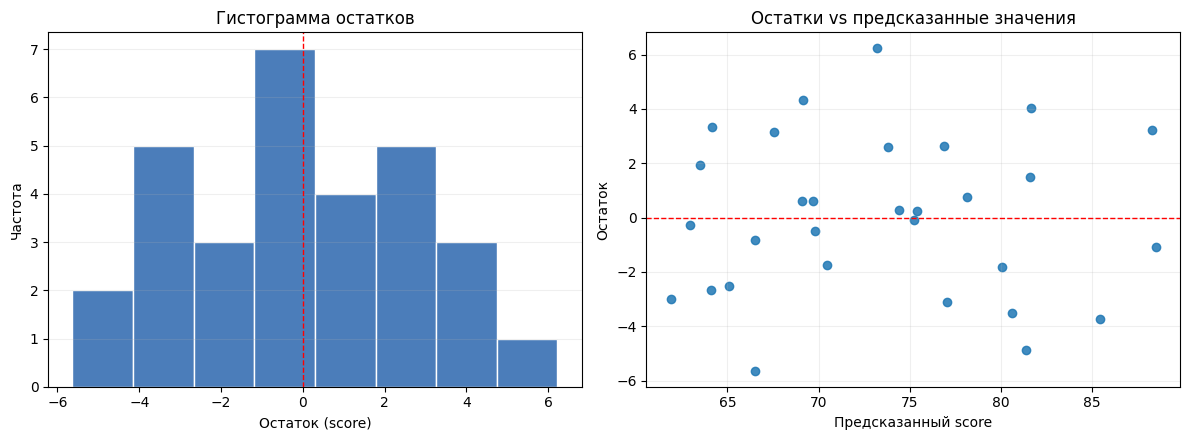

Среднее остатков = 0.0000
Стандартное отклонение остатков = 2.9289
Асимметрия остатков = 0.0613
Диапазон остатков = [-5.634, 6.223]
Максимальный |внешний стьюдентизированный остаток| = 2.170
Очищенный набор сохранён: practical_module_dataset_cleaned.csv (30 строк).


In [12]:
residuals = model_score.resid
fitted = model_score.fittedvalues
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(residuals, bins=8, color='#4B7DBA', edgecolor='white')
axes[0].axvline(0, color='red', linestyle='--', linewidth=1)
axes[0].set(title='Гистограмма остатков', xlabel='Остаток (score)', ylabel='Частота')
axes[0].grid(axis='y', alpha=0.2)
axes[1].scatter(fitted, residuals, alpha=0.85)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1].set(title='Остатки vs предсказанные значения', xlabel='Предсказанный score', ylabel='Остаток')
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f'Среднее остатков = {residuals.mean():.4f}')
print(f'Стандартное отклонение остатков = {residuals.std():.4f}')
print(f'Асимметрия остатков = {stats.skew(residuals, bias=False):.4f}')
print(f'Диапазон остатков = [{residuals.min():.3f}, {residuals.max():.3f}]')
print(f'Максимальный |внешний стьюдентизированный остаток| = '
      f'{np.max(np.abs(model_score.get_influence().resid_studentized_external)):.3f}')

cleaned_path = Path('practical_module_dataset_cleaned.csv')
df_clean.to_csv(cleaned_path, index=False)
print(f'Очищенный набор сохранён: {cleaned_path} ({len(df_clean)} строк).')

Остатки модели задания 6 сосредоточены около нуля и примерно симметричны (асимметрия `0.061`); сильной асимметрии или экстремальных выбросов по графикам не видно. Удалять наблюдения не потребовалось: очищенный CSV содержит все 30 исходных строк.